In [1]:
import pandas as pd
from urllib.parse import quote

# The physical and signal features we want to feed our model
FEATURES = [
    'koi_period', 'koi_duration', 'koi_depth', 'koi_prad', 
    'koi_teq', 'koi_insol', 'koi_model_snr', 'koi_steff', 'koi_srad'
]

# Building the SQL-like query to get the target label (koi_disposition), 
# the star ID (kepid), and our features from the 'cumulative' table
query = f"select kepid, koi_disposition, {', '.join(FEATURES)} from cumulative"

# Encoding the query into the API URL
url = ('https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=' 
       + quote(query) + '&format=csv')

print("Fetching data from NASA Exoplanet Archive...")
df = pd.read_csv(url)

print("Data loaded successfully!")
print(f"Dataset shape: {df.shape}")
df.head()

Fetching data from NASA Exoplanet Archive...
Data loaded successfully!
Dataset shape: (9564, 11)


,kepid,koi_disposition,koi_period,koi_duration,koi_depth,koi_prad,koi_teq,koi_insol,koi_model_snr,koi_steff,koi_srad
0,10797460,CONFIRMED,9.488036,2.95750,615.8,2.26,793.0,93.59,35.8,5455.0,0.927
1,10797460,CONFIRMED,54.418383,4.50700,874.8,2.83,443.0,9.11,25.8,5455.0,0.927
2,10811496,CANDIDATE,19.899140,1.78220,10829.0,14.60,638.0,39.30,76.3,5853.0,0.868
3,10848459,FALSE POSITIVE,1.736952,2.40641,8079.2,33.46,1395.0,891.96,505.6,5805.0,0.791
4,10854555,CONFIRMED,2.525592,1.65450,603.3,2.75,1406.0,926.16,40.9,6031.0,1.046


In [2]:
from sklearn.model_selection import GroupShuffleSplit

# Filter out candidates and drop rows with missing data
labeled = df[df.koi_disposition.isin(['CONFIRMED', 'FALSE POSITIVE'])].dropna()

# Define our X (features) and y (target label: 1 for Confirmed, 0 for False Positive)
X = labeled[FEATURES]
y = (labeled.koi_disposition == 'CONFIRMED').astype(int)

# Split by star (kepid), not by row, to prevent data leakage
split = GroupShuffleSplit(test_size=0.2, random_state=42)
train_idx, test_idx = next(split.split(X, y, groups=labeled.kepid))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Training set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")

Training set size: 5871 samples
Testing set size: 1457 samples


In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Initialize and train the Random Forest model
model = RandomForestClassifier(n_estimators=300, random_state=42)
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Output the performance metrics
print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.93      0.94       955
           1       0.88      0.92      0.90       502

    accuracy                           0.93      1457
   macro avg       0.92      0.93      0.92      1457
weighted avg       0.93      0.93      0.93      1457

Confusion Matrix:
[[890  65]
 [ 41 461]]


Running training size experiments...
Trained on 10.0% of data | F1 Score: 0.7502
Trained on 25.0% of data | F1 Score: 0.7683
Trained on 50.0% of data | F1 Score: 0.8843
Trained on 75.0% of data | F1 Score: 0.8912
Trained on 100.0% of data | F1 Score: 0.8969


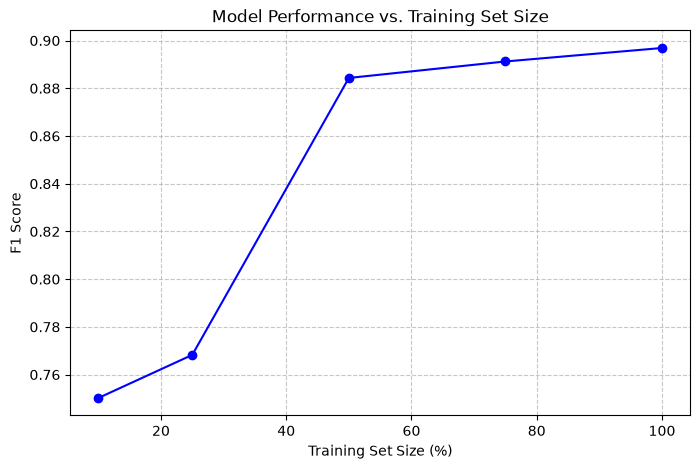

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
import numpy as np

# Training sizes to test (10%, 25%, 50%, 75%, 100%)
train_fractions = [0.10, 0.25, 0.50, 0.75, 1.0]
f1_scores = []

print("Running training size experiments...")

for frac in train_fractions:
    # Calculate the number of samples for the current fraction
    n_samples = int(frac * len(X_train))
    
    # Subsample the training data
    X_train_sub = X_train.iloc[:n_samples]
    y_train_sub = y_train.iloc[:n_samples]
    
    # Retrain the model on the subset
    model_sub = RandomForestClassifier(n_estimators=300, random_state=42)
    model_sub.fit(X_train_sub, y_train_sub)
    
    # Predict and calculate F1 score on the full test set
    y_pred_sub = model_sub.predict(X_test)
    f1 = f1_score(y_test, y_pred_sub)
    f1_scores.append(f1)
    
    print(f"Trained on {frac*100}% of data | F1 Score: {f1:.4f}")

# Plotting the learning curve
plt.figure(figsize=(8, 5))
plt.plot([frac * 100 for frac in train_fractions], f1_scores, marker='o', linestyle='-', color='b')
plt.title('Model Performance vs. Training Set Size')
plt.xlabel('Training Set Size (%)')
plt.ylabel('F1 Score')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [5]:
# Filter the original dataframe for just the CANDIDATE objects
candidates = df[df.koi_disposition == 'CANDIDATE'].copy()

# Drop missing values in the feature columns so the model can process them
candidates_clean = candidates.dropna(subset=FEATURES).copy()

# Extract the features for prediction
X_candidates = candidates_clean[FEATURES]

# Predict probabilities (index 1 is the probability of class 1 / 'CONFIRMED')
probabilities = model.predict_proba(X_candidates)[:, 1]

# Add the confidence scores to our dataframe
candidates_clean['confidence_score'] = probabilities

# Rank the candidates from highest confidence to lowest
top_candidates = candidates_clean.sort_values(by='confidence_score', ascending=False)

# Display the top 10 most likely new exoplanets along with their star ID
print("Top 10 Exoplanet Candidates (Ranked by Model Confidence):")
display(top_candidates[['kepid', 'confidence_score', 'koi_period', 'koi_prad']].head(10))

Top 10 Exoplanet Candidates (Ranked by Model Confidence):


,kepid,confidence_score,koi_period,koi_prad
7238,5956656,0.996667,46.245164,2.46
1824,9580992,0.996667,37.803412,2.95
537,8313667,0.996667,30.587215,2.32
1581,4242147,0.993333,28.782710,2.11
1496,11570749,0.990000,46.299105,4.33
744,10928043,0.990000,6.846399,1.90
5854,4947556,0.990000,141.608555,2.98
1535,3648437,0.990000,17.504417,3.56
812,4274548,0.986667,6.800820,1.88
2213,4172746,0.986667,17.699739,1.96
